## 1. 필요한 패키지 설치


In [1]:
# 필요한 패키지만 현재 커널에 설치한다.
# 현재 Jupyter 커널의 Python에 설치한다. OS의 기본 Python과 혼동하지 않는다.
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

DEPENDENCIES = {
    "torch": "torch>=2.2",
    "numpy": "numpy>=1.24",
    "pandas": "pandas>=2.0",
    "sklearn": "scikit-learn>=1.3",
    "sentencepiece": "sentencepiece==0.2.1",
    "konlpy": "konlpy==0.6.0",
    "jpype": "JPype1>=1.5",
    "matplotlib": "matplotlib>=3.7",
    "tqdm": "tqdm>=4.66",
}
missing = [package for module, package in DEPENDENCIES.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("필요한 Python 패키지가 이미 설치되어 있습니다.")

# Java가 없는 Colab에서만 설치한다. 로컬 PC의 Java 설정은 변경하지 않는다.
import shutil
is_colab = sys.platform.startswith("linux") and (Path("/content").exists() or "COLAB_RELEASE_TAG" in os.environ)
if is_colab and shutil.which("java") is None:
    subprocess.check_call(["apt-get", "update", "-qq"])
    subprocess.check_call(["apt-get", "install", "-y", "default-jre-headless"])


## 2. 라이브러리 불러오기 및 실행 장치 설정


In [2]:
# 라이브러리, 실행 장치, 난수 초기화.
import csv
import gc
import hashlib
import io
import json
import os
import platform
import random
import re
import time
import unicodedata
import urllib.request
from collections import Counter
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sentencepiece as spm
import torch
from IPython.display import Markdown, display
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, f1_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(min(4, os.cpu_count() or 1))

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

print("Python:", sys.version.split()[0], "| PyTorch:", torch.__version__)
print("실행 장치:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Python: 3.13.16 | PyTorch: 2.14.1+cu130
실행 장치: cuda
GPU: Tesla T4


## 3. 실험 설정


In [3]:
# 실험 설정. 제출용은 RUN_MODE="full", 동작 확인용은 "smoke".
RUN_MODE = "full"                 # "smoke" 또는 "full"
SPLIT_SEED = 42
MODEL_SEEDS = [42]                 # 반복 실험: [42, 52, 62]
MORPH_ANALYZERS = ["okt"]          # 추가 비교: ["okt", "kkma", "mecab"]
REQUIRE_GPU = True                 # full 모드의 실수로 인한 CPU 실행 방지
JVM_PATH = None                    # 예: r"C:\Program Files\...\bin\server\jvm.dll"
MECAB_DIC_PATH = None              # 기본 사전 경로와 다를 때만 지정

assert RUN_MODE in {"smoke", "full"}
CFG = {
    "max_len": 128, "embedding_dim": 128, "hidden_dim": 128,
    "dropout": 0.3, "batch_size": 128, "learning_rate": 1e-3,
    "weight_decay": 1e-4, "patience": 3, "min_delta": 1e-4,
    "epochs": 10 if RUN_MODE == "full" else 1,
    "train_limit": None if RUN_MODE == "full" else 1200,
    "val_limit": None if RUN_MODE == "full" else 300,
    "test_limit": None if RUN_MODE == "full" else 300,
    "model_types": ["unigram", "bpe"],
    "vocab_sizes": [4000, 8000, 16000] if RUN_MODE == "full" else [4000, 8000],
    "morph_vocab_size": 8000, "character_coverage": 0.9995,
}
BASE_DIR = Path.cwd() / "nsmc_artifacts"
DATA_DIR = BASE_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(SPLIT_SEED)
if RUN_MODE == "full" and REQUIRE_GPU and DEVICE.type != "cuda":
    raise RuntimeError("GPU가 연결되지 않았습니다. VS Code에서 Colab GPU 커널을 선택하고 다시 실행하세요.")
print(json.dumps({"mode": RUN_MODE, **CFG}, indent=2, ensure_ascii=False))
print("커널 Python:", sys.executable, "| 운영체제:", platform.system(), "| 장치:", DEVICE)


{
  "mode": "full",
  "max_len": 128,
  "embedding_dim": 128,
  "hidden_dim": 128,
  "dropout": 0.3,
  "batch_size": 128,
  "learning_rate": 0.001,
  "weight_decay": 0.0001,
  "patience": 3,
  "min_delta": 0.0001,
  "epochs": 10,
  "train_limit": null,
  "val_limit": null,
  "test_limit": null,
  "model_types": [
    "unigram",
    "bpe"
  ],
  "vocab_sizes": [
    4000,
    8000,
    16000
  ],
  "morph_vocab_size": 8000,
  "character_coverage": 0.9995
}
커널 Python: /usr/bin/python3 | 운영체제: Linux | 장치: cuda


## 4. NSMC 데이터 다운로드


In [4]:
# NSMC 공식 학습/테스트 파일 다운로드.
DATA_URLS = {
    "train": "https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt",
    "test": "https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt",
}

def sha256_file(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def download_file(url, path):
    if not path.exists():
        temporary = path.with_suffix(".download")
        request = urllib.request.Request(url, headers={"User-Agent": "NSMC-class-assignment"})
        with urllib.request.urlopen(request, timeout=90) as response:
            with temporary.open("wb") as output:
                shutil.copyfileobj(response, output)
        temporary.replace(path)
    return path

raw_frames, data_manifest = {}, {}
for split, url in DATA_URLS.items():
    path = download_file(url, DATA_DIR / f"ratings_{split}.txt")
    raw_frames[split] = pd.read_csv(path, sep="\t", quoting=csv.QUOTE_NONE,
                                    keep_default_na=False, dtype={"document": str})
    assert {"id", "document", "label"}.issubset(raw_frames[split].columns)
    data_manifest[split] = {"url": url, "sha256": sha256_file(path),
                            "raw_rows": len(raw_frames[split])}
display(pd.DataFrame(data_manifest).T)
display(raw_frames["train"].head())


,url,sha256,raw_rows
train,https://raw.githubusercontent.com/e9t/nsmc/mas...,e03b7d14e9e41be8d464a28057cd25d7396c53e67aa7fd...,150000
test,https://raw.githubusercontent.com/e9t/nsmc/mas...,8ac9f64052f11dbf6ae0acb5e038f03d90a76f0eda7820...,50000


,id,document,label
0,9976970,아 더빙.. 진짜 짜증나네요 목소리,0
1,3819312,흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나,1
2,10265843,너무재밓었다그래서보는것을추천한다,0
3,9045019,교도소 이야기구먼 ..솔직히 재미는 없다..평점 조정,0
4,6483659,사이몬페그의 익살스런 연기가 돋보였던 영화!스파이더맨에서 늙어보이기만 했던 커스틴 ...,1


## 5. 데이터 전처리 및 학습·검증·테스트 분할


In [5]:
# 정제 및 층화 분할. 학습 파일과 겹치는 테스트 문장을 제외하므로 원본 테스트 개수와 달라진다.
def normalize_text(text):
    if not isinstance(text, str):
        return ""
    return re.sub(r"\s+", " ", unicodedata.normalize("NFC", text)).strip()

def clean_frame(frame):
    result = frame.copy()
    result["text"] = result["document"].map(normalize_text)
    result["label"] = pd.to_numeric(result["label"], errors="coerce")
    result = result.loc[result["text"].ne("") & result["label"].isin([0, 1])].copy()
    result["label"] = result["label"].astype("int64")
    conflicts = result.groupby("text")["label"].nunique()
    conflicting_texts = set(conflicts[conflicts > 1].index)
    before = len(result)
    result = result.loc[~result["text"].isin(conflicting_texts)]
    conflict_rows = before - len(result)
    before = len(result)
    result = result.drop_duplicates("text").reset_index(drop=True)
    return result, {"raw": len(frame), "conflicting_rows_removed": conflict_rows,
                    "duplicate_rows_removed": before - len(result), "clean": len(result)}

train_pool, train_cleaning = clean_frame(raw_frames["train"])
test_df, test_cleaning = clean_frame(raw_frames["test"])
# 라벨 충돌로 제외한 리뷰까지 포함하여 공식 학습 파일의 전체 문장을 참조한다.
official_train_texts = set(raw_frames["train"]["document"].map(normalize_text))
overlap_mask = test_df["text"].isin(official_train_texts)
test_cleaning["train_overlap_removed"] = int(overlap_mask.sum())
test_df = test_df.loc[~overlap_mask].reset_index(drop=True)

train_df, val_df = train_test_split(train_pool, test_size=0.1,
                                   stratify=train_pool["label"], random_state=SPLIT_SEED)

def stratified_limit(frame, limit):
    if limit is None or len(frame) <= limit:
        return frame.reset_index(drop=True)
    subset, _ = train_test_split(frame, train_size=limit, stratify=frame["label"],
                                 random_state=SPLIT_SEED)
    return subset.reset_index(drop=True)

train_df = stratified_limit(train_df, CFG["train_limit"])
val_df = stratified_limit(val_df, CFG["val_limit"])
test_df = stratified_limit(test_df, CFG["test_limit"])
assert set(train_df.text).isdisjoint(val_df.text)
assert set(train_df.text).isdisjoint(test_df.text)
assert set(val_df.text).isdisjoint(test_df.text)
assert all(set(frame.label) == {0, 1} for frame in [train_df, val_df, test_df])

split_summary = pd.DataFrame([
    {"split": name, "rows": len(frame), "positive_ratio": frame.label.mean(),
     "mean_characters": frame.text.str.len().mean()}
    for name, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]
])
display(pd.DataFrame({"train": train_cleaning, "test": test_cleaning}).T)
display(split_summary)

def frame_hash(frame):
    payload = frame[["id", "text", "label"]].to_json(orient="records", force_ascii=False)
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()

environment = {name: version(name) for name in [
    "torch", "numpy", "pandas", "scikit-learn", "sentencepiece", "konlpy", "JPype1", "matplotlib"]}
environment.update({"python": sys.version, "platform": platform.platform(), "device": str(DEVICE)})
run_config = {"mode": RUN_MODE, "split_seed": SPLIT_SEED, "model_seeds": MODEL_SEEDS,
              "morph_analyzers": MORPH_ANALYZERS, "jvm_path": JVM_PATH,
              "mecab_dic_path": MECAB_DIC_PATH, "config": CFG, "environment": environment,
              "split_hashes": {name: frame_hash(frame) for name, frame in
                               [("train", train_df), ("validation", val_df), ("test", test_df)]}}
run_id = hashlib.sha256(json.dumps(run_config, sort_keys=True).encode()).hexdigest()[:12]
RUN_DIR = BASE_DIR / f"{RUN_MODE}_{run_id}"
RUN_DIR.mkdir(parents=True, exist_ok=True)

def save_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")

save_json(RUN_DIR / "config.json", run_config)
save_json(RUN_DIR / "environment.json", environment)
save_json(RUN_DIR / "data_manifest.json", {"source": data_manifest,
          "cleaning": {"train": train_cleaning, "test": test_cleaning}})
split_summary.to_csv(RUN_DIR / "split_summary.csv", index=False)
for name, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    frame[["id", "label"]].to_csv(RUN_DIR / f"{name}_ids.csv", index=False)
print("결과 저장 경로:", RUN_DIR.resolve())


,raw,conflicting_rows_removed,duplicate_rows_removed,clean,train_overlap_removed
train,150000.0,1451.0,2519.0,146025.0,NaN
test,50000.0,306.0,581.0,49110.0,752.0


,split,rows,positive_ratio,mean_characters
0,train,131422,0.498219,36.042656
1,validation,14603,0.498254,36.108745
2,test,48358,0.503019,36.341040


결과 저장 경로: /content/nsmc_artifacts/full_5cccd57e03e0


## 6. 코퍼스 분포 및 문장 길이 분석


학습 문장 길이 분포(문자 수):


,characters
count,131422.000000
mean,36.042656
std,29.532622
min,1.000000
50%,27.000000
90%,76.000000
95%,108.000000
99%,139.000000
max,158.000000


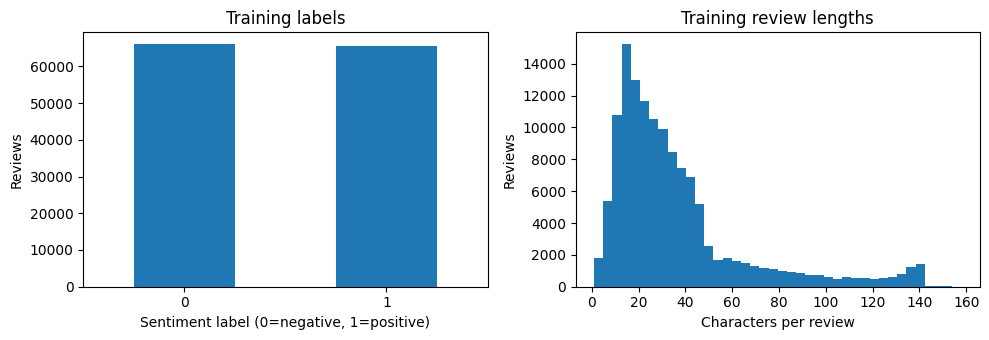

In [6]:
# 코퍼스의 라벨 분포와 문장 길이 확인.
# 루브릭 1: 코퍼스 분포와 길이를 실제 출력으로 남긴다.
print("학습 문장 길이 분포(문자 수):")
display(train_df.text.str.len().describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame("characters"))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
train_df.label.value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set(xlabel="Sentiment label (0=negative, 1=positive)", ylabel="Reviews", title="Training labels")
axes[1].hist(train_df.text.str.len(), bins=40)
axes[1].set(xlabel="Characters per review", ylabel="Reviews", title="Training review lengths")
fig.tight_layout()
fig.savefig(RUN_DIR / "corpus_analysis.png", dpi=160)
plt.show()


## 7. KoNLPy 형태소 분석기 초기화


In [7]:
# 형태소 분석기 초기화. 사용할 수 없는 분석기의 사유를 기록한다.
from konlpy.tag import Kkma, Mecab, Okt

analyzers = {}
analyzer_status = []
for name in MORPH_ANALYZERS:
    if name not in {"okt", "kkma", "mecab"}:
        raise ValueError(f"지원하지 않는 분석기: {name}")
    try:
        if name == "okt":
            analyzer = Okt(jvmpath=JVM_PATH, max_heap_size=2048)
        elif name == "kkma":
            analyzer = Kkma(jvmpath=JVM_PATH, max_heap_size=2048)
        else:
            if platform.system() == "Windows":
                raise RuntimeError("KoNLPy Mecab은 Windows 미지원; Linux/WSL/Colab에서 설치 후 실행")
            analyzer = Mecab(**({"dicpath": MECAB_DIC_PATH} if MECAB_DIC_PATH else {}))
        pieces = analyzer.morphs("영화가 정말 재미있어요! ㅋㅋ")
        analyzers[name] = analyzer
        analyzer_status.append({"analyzer": name, "status": "available", "reason": ""})
        print(name, "→", pieces)
    except Exception as exc:
        analyzer_status.append({"analyzer": name, "status": "skipped",
                                "reason": f"{type(exc).__name__}: {exc}"})
status_df = pd.DataFrame(analyzer_status)
status_df.to_csv(RUN_DIR / "analyzer_status.csv", index=False, encoding="utf-8-sig")
display(status_df)
if not analyzers:
    raise RuntimeError("KoNLPy 분석기가 하나도 없습니다. Java/JVM_PATH 또는 MeCab 설치를 확인하고 다시 실행하세요.")


okt → ['영화', '가', '정말', '재미있어요', '!', 'ㅋㅋ']


,analyzer,status,reason
0,okt,available,


## 8. SentencePiece 모델 학습


In [8]:
# SentencePiece는 학습 분할만 사용해 학습한다. 검증/테스트는 포함하지 않는다.
SP_DIR = RUN_DIR / "sentencepiece"
SP_DIR.mkdir(exist_ok=True)
sp_corpus_path = SP_DIR / "train_only.txt"
sp_corpus_path.write_text("\n".join(train_df.text) + "\n", encoding="utf-8")

def train_sentencepiece(model_type, vocab_size):
    prefix = SP_DIR / f"{model_type}_{vocab_size}"
    model_path = prefix.with_suffix(".model")
    if not model_path.exists():
        buffer = io.BytesIO()
        with sp_corpus_path.open("r", encoding="utf-8") as sentences:
            spm.SentencePieceTrainer.train(
                sentence_iterator=sentences, model_writer=buffer,
                model_type=model_type, vocab_size=vocab_size,
                character_coverage=CFG["character_coverage"],
                pad_id=0, unk_id=1, bos_id=-1, eos_id=-1,
                normalization_rule_name="identity", hard_vocab_limit=False,
                input_sentence_size=0, shuffle_input_sentence=False,
                num_threads=1, max_sentence_length=16384, minloglevel=1,
            )
        model_path.write_bytes(buffer.getvalue())
    processor = spm.SentencePieceProcessor(model_proto=model_path.read_bytes())
    vocab_lines = [f"{processor.id_to_piece(i)}\t{processor.get_score(i)}"
                   for i in range(processor.get_piece_size())]
    prefix.with_suffix(".vocab").write_text("\n".join(vocab_lines) + "\n", encoding="utf-8")
    assert processor.pad_id() == 0 and processor.unk_id() == 1
    return processor, model_path

baseline_sp, baseline_sp_path = train_sentencepiece("unigram", 8000)
print("실제 어휘 수:", baseline_sp.get_piece_size())
for text in train_df.text.head(3):
    print("문장:", text)
    print("조각:", baseline_sp.encode(text, out_type=str))
    print("ID  :", baseline_sp.encode(text, out_type=int))


실제 어휘 수: 8000
문장: 요즘영화애선 느낄수없는 그때만의 영화도 좋다..전지현 너무 이쁘더라 음악도 좋고 한편의 소설을 몰입해서 읽은듯하다
조각: ['▁요즘', '영화', '애', '선', '▁느낄수', '없는', '▁그때', '만', '의', '▁영화도', '▁좋다', '..', '전', '지', '현', '▁너무', '▁이쁘', '더라', '▁음악도', '▁좋고', '▁한편의', '▁소설을', '▁몰입해서', '▁읽', '은', '듯하다']
ID  : [503, 30, 443, 265, 2904, 254, 1730, 22, 8, 1701, 359, 5, 146, 18, 521, 23, 2358, 747, 3066, 714, 5263, 5040, 3246, 2437, 16, 4935]
문장: 역겨운 남자들끼리의 빨구리가 전부인 영화 사무라이 영화아님!
조각: ['▁역겨운', '▁남자', '들끼리', '의', '▁빨', '구리', '가', '▁전부', '인', '▁영화', '▁사무라이', '▁영화', '아님', '!']
ID  : [5515, 472, 4683, 8, 2831, 5298, 10, 1193, 38, 6, 7079, 6, 2817, 24]
문장: 일본을 저주하면서 일본만화는 베껴서라도 돈을 벌겠다는 미개한 사고방식에 찌든 사람들.
조각: ['▁일본', '을', '▁저', '주', '하면서', '▁일본', '만화', '는', '▁베', '껴', '서', '라도', '▁돈을', '▁벌', '겠다', '는', '▁미', '개', '한', '▁사고', '방식', '에', '▁찌', '든', '▁사람들', '.']
ID  : [316, 13, 188, 101, 751, 316, 2607, 11, 859, 4115, 58, 718, 4569, 2345, 414, 11, 297, 185, 20, 4512, 5039, 14, 3287, 367, 803, 3]


## 9. sp_tokenize() 구현 및 동작 확인


In [9]:
# SentencePiece ID 변환 및 오른쪽 패딩. PAD=0, UNK=1.
def pad_id_sequences(sequences, maxlen, pad_id=0, unk_id=1):
    if maxlen < 1:
        raise ValueError("maxlen은 1 이상이어야 합니다.")
    matrix = np.full((len(sequences), maxlen), pad_id, dtype=np.int32)
    for row, sequence in enumerate(sequences):
        ids = list(sequence)[:maxlen] or [unk_id]
        matrix[row, :len(ids)] = ids
    return matrix

def sp_tokenize(sp, corpus, maxlen=128):
    '''학습된 SentencePieceProcessor로 ID 행렬과 양방향 어휘 사전을 반환한다.'''
    if isinstance(corpus, str):
        raise TypeError("문장 하나도 [문장]처럼 iterable로 전달하세요.")
    texts = [normalize_text(text) for text in corpus]
    sequences = sp.encode(texts, out_type=int)
    tensor = pad_id_sequences(sequences, maxlen, sp.pad_id(), sp.unk_id())
    word_index = {sp.id_to_piece(i): i for i in range(sp.get_piece_size())}
    index_word = {i: token for token, i in word_index.items()}
    return tensor, word_index, index_word

sample_tensor, word_index, index_word = sp_tokenize(
    baseline_sp, ["정말 재밌는 영화네요 ㅋㅋ", "시간이 아까운 영화", ""], maxlen=20)
print("shape:", sample_tensor.shape, "dtype:", sample_tensor.dtype)
print(sample_tensor)
assert sample_tensor.shape == (3, 20)
assert sample_tensor[2, 0] == 1 and np.all(sample_tensor[2, 1:] == 0)
assert word_index["<pad>"] == 0 and word_index["<unk>"] == 1
assert max(index_word) < baseline_sp.get_piece_size()


shape: (3, 20) dtype: int32
[[  27  791 1083  120    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0]
 [ 609  634    6    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0]
 [   1    0    0    0    0    0    0    0    0    0    0    0    0    0
     0    0    0    0    0    0]]


## 10. 형태소 어휘 생성 및 공통 인코딩 구현


In [10]:
# 형태소 어휘도 학습 분할의 빈도로만 생성한다. 모든 방식에 같은 길이 제한을 적용한다.
def morph_tokenize(name, texts, cache_name):
    cache_path = RUN_DIR / f"{name}_{cache_name}_tokens.json"
    if cache_path.exists():
        return json.loads(cache_path.read_text(encoding="utf-8"))
    tokens = []
    for text in tqdm(texts, desc=f"{name}: {cache_name}"):
        if name == "okt":
            row = analyzers[name].morphs(text, norm=False, stem=False)
        else:
            row = analyzers[name].morphs(text)
        tokens.append(row)
    save_json(cache_path, tokens)
    return tokens

def build_morph_vocab(tokenized_train, vocab_size):
    counts = Counter(token for row in tokenized_train for token in row)
    ordered = sorted(counts, key=lambda token: (-counts[token], token))
    vocab = {"<pad>": 0, "<unk>": 1}
    for token in ordered:
        if token not in vocab and len(vocab) < vocab_size:
            vocab[token] = len(vocab)
    return vocab

def create_sp_spec(model_type, vocab_size):
    started = time.perf_counter()
    processor, path = train_sentencepiece(model_type, vocab_size)
    return {"name": f"sp_{model_type}_{vocab_size}", "family": "sentencepiece",
            "model_type": model_type, "requested_vocab": vocab_size,
            "actual_vocab": processor.get_piece_size(), "sp": processor,
            "tokenizer_path": str(path), "setup_or_load_seconds": time.perf_counter() - started}

def create_morph_spec(name):
    started = time.perf_counter()
    tokenized_train = morph_tokenize(name, train_df.text.tolist(), "train")
    vocab = build_morph_vocab(tokenized_train, CFG["morph_vocab_size"])
    path = RUN_DIR / f"{name}_vocab.json"
    save_json(path, vocab)
    return {"name": f"morph_{name}_{CFG['morph_vocab_size']}", "family": "konlpy",
            "model_type": name, "requested_vocab": CFG["morph_vocab_size"],
            "actual_vocab": len(vocab), "vocab": vocab, "analyzer": name,
            "tokenizer_path": str(path), "setup_or_load_seconds": time.perf_counter() - started}

def encode_frame(spec, frame, split):
    texts = frame.text.tolist()
    if spec["family"] == "sentencepiece":
        sequences = spec["sp"].encode(texts, out_type=int)
        # 과제에서 구현한 sp_tokenize()를 학습과 평가에 실제로 사용한다.
        matrix, _, _ = sp_tokenize(spec["sp"], texts, maxlen=CFG["max_len"])
    else:
        token_rows = morph_tokenize(spec["analyzer"], texts, split)
        sequences = [[spec["vocab"].get(token, 1) for token in row] for row in token_rows]
        matrix = pad_id_sequences(sequences, CFG["max_len"])
    lengths = np.asarray([len(row) for row in sequences])
    used_tokens = sum(min(len(row), CFG["max_len"]) for row in sequences)
    unknowns = sum(row[:CFG["max_len"]].count(1) for row in sequences)
    diagnostics = {"mean_tokens": float(lengths.mean()),
                   "p95_tokens": float(np.percentile(lengths, 95)),
                   "truncated_fraction": float(np.mean(lengths > CFG["max_len"])),
                   "unk_fraction": unknowns / max(used_tokens, 1),
                   "empty_fraction": float(np.mean(lengths == 0))}
    assert matrix.min() >= 0 and matrix.max() < spec["actual_vocab"]
    return matrix, diagnostics

def metadata_only(spec):
    return {key: value for key, value in spec.items() if key not in {"sp", "vocab"}}


## 11. BiGRU 분류기 및 학습·평가 함수 정의


In [11]:
# 공통 BiGRU 분류기. 검증 Accuracy 기준으로 체크포인트 선택 및 조기 종료.
class ReviewDataset(Dataset):
    def __init__(self, matrix, labels):
        self.matrix = matrix
        self.labels = np.asarray(labels, dtype=np.float32)
        self.lengths = np.maximum((matrix != 0).sum(axis=1), 1)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        length = int(self.lengths[index])
        return self.matrix[index, :length], self.labels[index]

def collate_batch(batch):
    lengths = torch.tensor([len(row) for row, _ in batch], dtype=torch.long)
    inputs = torch.zeros((len(batch), int(lengths.max())), dtype=torch.long)
    for index, (row, _) in enumerate(batch):
        inputs[index, :len(row)] = torch.as_tensor(row, dtype=torch.long)
    labels = torch.tensor([label for _, label in batch], dtype=torch.float32)
    return inputs, lengths, labels

def make_loader(matrix, labels, shuffle=False, seed=42):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(ReviewDataset(matrix, labels), batch_size=CFG["batch_size"],
                      shuffle=shuffle, collate_fn=collate_batch, num_workers=0,
                      generator=generator, pin_memory=(DEVICE.type == "cuda"))

class BiGRUSentiment(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, CFG["embedding_dim"], padding_idx=0)
        self.gru = nn.GRU(CFG["embedding_dim"], CFG["hidden_dim"],
                          batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(CFG["dropout"])
        self.output = nn.Linear(CFG["hidden_dim"] * 2, 1)

    def forward(self, inputs, lengths):
        embedded = self.embedding(inputs)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True,
                                       enforce_sorted=False)
        _, hidden = self.gru(packed)
        representation = torch.cat([hidden[-2], hidden[-1]], dim=1)
        return self.output(self.dropout(representation)).squeeze(1)

def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    true_labels, probabilities = [], []
    total_loss = 0.0
    criterion = nn.BCEWithLogitsLoss(reduction="sum")
    for inputs, lengths, labels in loader:
        logits = model(inputs.to(DEVICE), lengths)
        total_loss += criterion(logits, labels.to(DEVICE)).item()
        true_labels.extend(labels.numpy().astype(int).tolist())
        probabilities.extend(torch.sigmoid(logits).cpu().numpy().tolist())
    labels = np.asarray(true_labels)
    probs = np.asarray(probabilities)
    preds = (probs >= 0.5).astype(int)
    return {"loss": total_loss / len(labels), "accuracy": accuracy_score(labels, preds),
            "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
            "positive_f1": f1_score(labels, preds, zero_division=0),
            "roc_auc": roc_auc_score(labels, probs)}, probs

def fit_classifier(spec, train_matrix, val_matrix, seed):
    seed_everything(seed)
    model = BiGRUSentiment(spec["actual_vocab"]).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["learning_rate"],
                                  weight_decay=CFG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=1, min_lr=1e-5)
    criterion = nn.BCEWithLogitsLoss()
    train_loader = make_loader(train_matrix, train_df.label, shuffle=True, seed=seed)
    val_loader = make_loader(val_matrix, val_df.label)
    checkpoint_dir = RUN_DIR / "checkpoints"
    checkpoint_dir.mkdir(exist_ok=True)
    checkpoint = checkpoint_dir / f"{spec['name']}_seed{seed}.pt"
    best_score, best_epoch, stale = -1.0, 0, 0
    history = []
    synchronize()
    started = time.perf_counter()
    for epoch in range(1, CFG["epochs"] + 1):
        model.train()
        loss_sum = 0.0
        correct = 0
        for inputs, lengths, labels in tqdm(train_loader, desc=f"{spec['name']} / {seed} / epoch {epoch}", leave=False):
            optimizer.zero_grad(set_to_none=True)
            logits = model(inputs.to(DEVICE), lengths)
            loss = criterion(logits, labels.to(DEVICE))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            loss_sum += loss.item() * len(labels)
            correct += int(((logits.detach() >= 0).cpu() == (labels >= 0.5)).sum())
        val_metrics, _ = evaluate(model, val_loader)
        history.append({"epoch": epoch, "train_loss": loss_sum / len(train_df),
                        "train_accuracy": correct / len(train_df),
                        "learning_rate": optimizer.param_groups[0]["lr"],
                        **{f"val_{key}": value for key, value in val_metrics.items()}})
        scheduler.step(val_metrics["accuracy"])
        print(f"{spec['name']} seed={seed} epoch={epoch}: "
              f"val_acc={val_metrics['accuracy']:.4f}, val_macro_f1={val_metrics['macro_f1']:.4f}")
        if val_metrics["accuracy"] > best_score + CFG["min_delta"]:
            best_score, best_epoch, stale = val_metrics["accuracy"], epoch, 0
            torch.save(model.state_dict(), checkpoint)
        else:
            stale += 1
            if stale >= CFG["patience"]:
                break
    synchronize()
    training_seconds = time.perf_counter() - started
    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
    best_metrics, _ = evaluate(model, val_loader)
    pd.DataFrame(history).to_csv(RUN_DIR / f"{spec['name']}_seed{seed}_history.csv", index=False)
    result = {**metadata_only(spec), "seed": seed, "best_epoch": best_epoch,
              "parameters": sum(p.numel() for p in model.parameters()),
              "training_seconds": training_seconds, "checkpoint": str(checkpoint),
              **{f"val_{key}": value for key, value in best_metrics.items()}}
    del model, optimizer, train_loader, val_loader
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return result


## 12. 토크나이저별 감정 분류 모델 학습


In [12]:
# 동일한 데이터와 분류기 구조로 각 토크나이저를 비교한다.
specs = []
validation_rows = []
diagnostic_rows = []

experiment_plan = [("sentencepiece", model_type, vocab_size)
                   for model_type in CFG["model_types"] for vocab_size in CFG["vocab_sizes"]]
experiment_plan += [("konlpy", name, CFG["morph_vocab_size"]) for name in analyzers]

for family, tokenizer_type, vocab_size in experiment_plan:
    spec = (create_sp_spec(tokenizer_type, vocab_size) if family == "sentencepiece"
            else create_morph_spec(tokenizer_type))
    specs.append(spec)
    started = time.perf_counter()
    train_matrix, train_diagnostics = encode_frame(spec, train_df, "train")
    val_matrix, val_diagnostics = encode_frame(spec, val_df, "validation")
    encoding_seconds = time.perf_counter() - started
    for split, diagnostics in [("train", train_diagnostics), ("validation", val_diagnostics)]:
        diagnostic_rows.append({"name": spec["name"], "split": split, **diagnostics})
    save_json(RUN_DIR / f"{spec['name']}_tokenizer.json", metadata_only(spec))
    for seed in MODEL_SEEDS:
        row = fit_classifier(spec, train_matrix, val_matrix, seed)
        row["encoding_or_cache_seconds"] = encoding_seconds
        validation_rows.append(row)
        pd.DataFrame(validation_rows).to_csv(RUN_DIR / "validation_runs.csv", index=False)
    del train_matrix, val_matrix
    gc.collect()

validation_runs = pd.DataFrame(validation_rows)
diagnostics_df = pd.DataFrame(diagnostic_rows)
diagnostics_df.to_csv(RUN_DIR / "tokenization_diagnostics.csv", index=False)
save_json(RUN_DIR / "tokenizer_registry.json", [metadata_only(spec) for spec in specs])
display(validation_runs[["name", "seed", "actual_vocab", "parameters", "best_epoch",
                         "val_accuracy", "val_macro_f1", "training_seconds"]])


sp_unigram_4000 / 42 / epoch 1:   0%|          | 0/1027 [00:00<?, ?it/s]

sp_unigram_4000 seed=42 epoch=1: val_acc=0.8367, val_macro_f1=0.8367


sp_unigram_4000 / 42 / epoch 2:   0%|          | 0/1027 [00:00<?, ?it/s]

sp_unigram_4000 seed=42 epoch=2: val_acc=0.8485, val_macro_f1=0.8485


sp_unigram_4000 / 42 / epoch 3:   0%|          | 0/1027 [00:00<?, ?it/s]

sp_unigram_4000 seed=42 epoch=3: val_acc=0.8565, val_macro_f1=0.8565


... (83 outputs left out)

morph_okt_8000 seed=42 epoch=6: val_acc=0.8456, val_macro_f1=0.8455


morph_okt_8000 / 42 / epoch 7:   0%|          | 0/1027 [00:00<?, ?it/s]

morph_okt_8000 seed=42 epoch=7: val_acc=0.8433, val_macro_f1=0.8432


,name,seed,actual_vocab,parameters,best_epoch,val_accuracy,val_macro_f1,training_seconds
0,sp_unigram_4000,42,4000,710401,3,0.856536,0.856467,103.396439
1,sp_unigram_8000,42,8000,1222401,3,0.854619,0.854618,96.031860
2,sp_unigram_16000,42,16000,2246401,4,0.854140,0.854017,109.061003
3,sp_bpe_4000,42,4000,710401,3,0.850921,0.850910,102.329868
4,sp_bpe_8000,42,8000,1222401,3,0.853386,0.853385,95.209374
5,sp_bpe_16000,42,16000,2246401,4,0.846401,0.846349,109.196605
6,morph_okt_8000,42,8000,1222401,4,0.854003,0.853988,100.900264


## 13. 검증 성능 비교 및 최적 설정 선택


,name,family,model_type,requested_vocab,actual_vocab,val_macro_f1_mean,val_macro_f1_std,val_accuracy_mean,mean_training_seconds,parameters,runs,comparison_group
0,sp_unigram_4000,sentencepiece,unigram,4000,4000,0.856467,NaN,0.856536,103.396439,710401,1,sentencepiece
1,sp_unigram_8000,sentencepiece,unigram,8000,8000,0.854618,NaN,0.854619,96.031860,1222401,1,sentencepiece
2,sp_unigram_16000,sentencepiece,unigram,16000,16000,0.854017,NaN,0.854140,109.061003,2246401,1,sentencepiece
3,morph_okt_8000,konlpy,okt,8000,8000,0.853988,NaN,0.854003,100.900264,1222401,1,okt
4,sp_bpe_8000,sentencepiece,bpe,8000,8000,0.853385,NaN,0.853386,95.209374,1222401,1,sentencepiece
5,sp_bpe_4000,sentencepiece,bpe,4000,4000,0.850910,NaN,0.850921,102.329868,710401,1,sentencepiece
6,sp_bpe_16000,sentencepiece,bpe,16000,16000,0.846349,NaN,0.846401,109.196605,2246401,1,sentencepiece


model_type,bpe,unigram
requested_vocab,,
4000,0.850910,0.856467
8000,0.853385,0.854618
16000,0.846349,0.854017


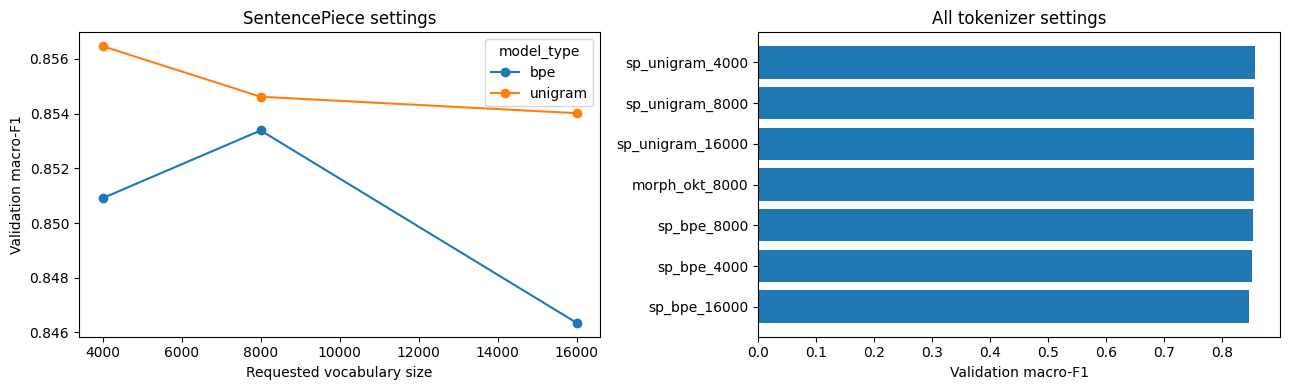

검증으로 선택한 설정: ['sp_unigram_4000', 'morph_okt_8000']


,name,split,mean_tokens,p95_tokens,truncated_fraction,unk_fraction,empty_fraction
1,sp_unigram_4000,validation,20.332260,62.0,0.0,0.000943,0.0
3,sp_unigram_8000,validation,17.481613,53.0,0.0,0.001097,0.0
5,sp_unigram_16000,validation,15.603095,47.0,0.0,0.001229,0.0
7,sp_bpe_4000,validation,19.880983,60.9,0.0,0.000964,0.0
9,sp_bpe_8000,validation,17.113949,52.0,0.0,0.001120,0.0
11,sp_bpe_16000,validation,15.302198,46.0,0.0,0.001253,0.0
13,morph_okt_8000,validation,14.736629,44.0,0.0,0.123137,0.0


In [13]:
# 설정은 검증 Accuracy로 선택하고, 동점은 macro-F1로 비교한다.
validation_summary = validation_runs.groupby(
    ["name", "family", "model_type", "requested_vocab", "actual_vocab"], as_index=False
).agg(val_macro_f1_mean=("val_macro_f1", "mean"),
      val_macro_f1_std=("val_macro_f1", "std"),
      val_accuracy_mean=("val_accuracy", "mean"),
      mean_training_seconds=("training_seconds", "mean"),
      parameters=("parameters", "first"), runs=("seed", "count"))
# seed 1개일 때 표준편차는 계산할 수 없으므로 NaN을 그대로 둔다.
validation_summary["comparison_group"] = np.where(
    validation_summary.family.eq("sentencepiece"), "sentencepiece", validation_summary.model_type)
validation_summary = validation_summary.sort_values(
    ["val_accuracy_mean", "val_macro_f1_mean", "name"], ascending=[False, False, True]).reset_index(drop=True)
validation_summary.to_csv(RUN_DIR / "validation_summary.csv", index=False)
display(validation_summary)

sp_summary = validation_summary.query("family == 'sentencepiece'")
sp_pivot = sp_summary.pivot(index="requested_vocab", columns="model_type", values="val_macro_f1_mean")
display(sp_pivot)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sp_pivot.plot(marker="o", ax=axes[0])
axes[0].set(xlabel="Requested vocabulary size", ylabel="Validation macro-F1",
            title="SentencePiece settings")
chart = validation_summary.sort_values("val_macro_f1_mean")
axes[1].barh(chart.name, chart.val_macro_f1_mean)
axes[1].set(xlabel="Validation macro-F1", title="All tokenizer settings")
fig.tight_layout()
fig.savefig(RUN_DIR / "validation_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

selected = validation_summary.drop_duplicates("comparison_group").copy()
selected_names = selected.name.tolist()
selected.to_csv(RUN_DIR / "selected_by_validation.csv", index=False)
print("검증으로 선택한 설정:", selected_names)
display(diagnostics_df.query("split == 'validation'"))


## 14. 테스트 데이터 최종 평가


okt: test:   0%|          | 0/48358 [00:00<?, ?it/s]

,name,family,model_type,actual_vocab,test_accuracy_mean,test_accuracy_std,test_macro_f1_mean,test_macro_f1_std,test_positive_f1_mean,test_roc_auc_mean,runs
0,morph_okt_8000,konlpy,okt,8000,0.846602,NaN,0.846600,NaN,0.846029,0.927897,1
1,sp_unigram_4000,sentencepiece,unigram,4000,0.849477,NaN,0.849435,NaN,0.846929,0.930029,1


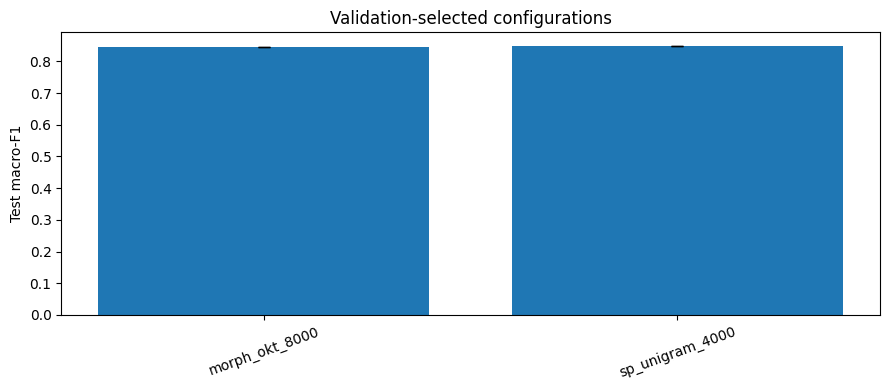

In [14]:
# 선택한 설정을 고정한 후 테스트를 평가한다. 테스트 점수로 추가 튜닝하지 않는다.
spec_by_name = {spec["name"]: spec for spec in specs}
test_rows = []
prediction_frames = {}

for name in selected_names:
    spec = spec_by_name[name]
    test_matrix, test_diagnostics = encode_frame(spec, test_df, "test")
    diagnostic_rows.append({"name": name, "split": "test", **test_diagnostics})
    loader = make_loader(test_matrix, test_df.label)
    for row in validation_runs.loc[validation_runs.name.eq(name)].to_dict("records"):
        model = BiGRUSentiment(spec["actual_vocab"]).to(DEVICE)
        model.load_state_dict(torch.load(row["checkpoint"], map_location=DEVICE, weights_only=True))
        metrics, probabilities = evaluate(model, loader)
        test_rows.append({"name": name, "family": spec["family"], "model_type": spec["model_type"],
                          "seed": row["seed"], "actual_vocab": spec["actual_vocab"],
                          **{f"test_{key}": value for key, value in metrics.items()}})
        predictions = test_df[["id", "text", "label"]].copy()
        predictions["positive_probability"] = probabilities
        predictions["prediction"] = (probabilities >= 0.5).astype(int)
        predictions.to_csv(RUN_DIR / f"{name}_seed{row['seed']}_test_predictions.csv",
                           index=False, encoding="utf-8-sig")
        prediction_frames[(name, row["seed"])] = predictions
        del model
    del test_matrix, loader
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

test_runs = pd.DataFrame(test_rows)
test_summary = test_runs.groupby(["name", "family", "model_type", "actual_vocab"], as_index=False).agg(
    test_accuracy_mean=("test_accuracy", "mean"), test_accuracy_std=("test_accuracy", "std"),
    test_macro_f1_mean=("test_macro_f1", "mean"), test_macro_f1_std=("test_macro_f1", "std"),
    test_positive_f1_mean=("test_positive_f1", "mean"), test_roc_auc_mean=("test_roc_auc", "mean"),
    runs=("seed", "count"))
test_runs.to_csv(RUN_DIR / "test_runs.csv", index=False)
test_summary.to_csv(RUN_DIR / "test_summary.csv", index=False)
pd.DataFrame(diagnostic_rows).to_csv(RUN_DIR / "tokenization_diagnostics.csv", index=False)
display(test_summary)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(test_summary.name, test_summary.test_macro_f1_mean,
       yerr=test_summary.test_macro_f1_std.fillna(0).to_numpy(), capsize=4)
ax.set(ylabel="Test macro-F1", title="Validation-selected configurations")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(RUN_DIR / "test_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


## 15. 오분류 분석 및 학습 곡선 확인


              precision    recall  f1-score   support

    negative       0.83      0.87      0.85     24033
    positive       0.87      0.83      0.85     24325

    accuracy                           0.85     48358
   macro avg       0.85      0.85      0.85     48358
weighted avg       0.85      0.85      0.85     48358



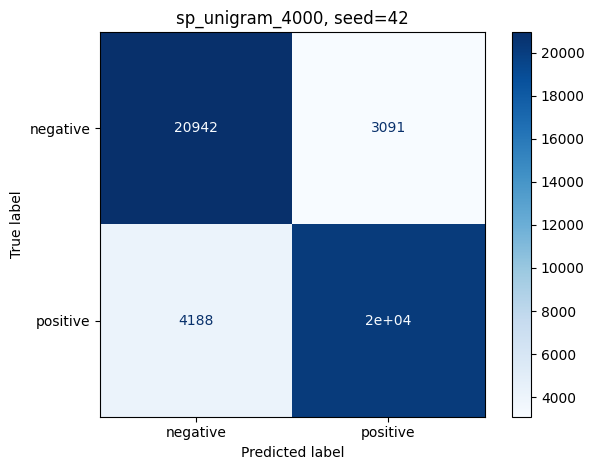

,id,text,label,positive_probability,prediction,confidence
42411,6571875,무서운것도적당것하고 뭐재밋네요 재미있게봤어요^^,0,0.999427,1,0.999427
11092,4503404,볼수록 감탄하고 또 엄청나게 재밌는 작품 장면장면이 다 환상적이다 위대한 영화,0,0.999414,1,0.999414
5268,4311327,와 이거 대박!너무 재밌는거 아냐!!!강추~ 강추!소장용으로 강추!연인과함께 강추!,0,0.999408,1,0.999408
9024,7448193,재밌네요^^ 브래드피트 멋있어요^^,0,0.999299,1,0.999299
30794,6080537,와 이영화 재밌다....와 이영화 재밌다....와 이영화 재밌다....와 이영화 재...,0,0.999281,1,0.999281
17556,8813840,순수한영화입니다 10점 만점에10점짜리!!!^^♡,0,0.999209,1,0.999209
39898,8519651,굿굿 명작입니다. 베리굿.,0,0.999180,1,0.999180
14750,8767602,와 정말 재밌다 꼭 추천합니다.,0,0.998917,1,0.998917
46851,6997581,최고최고!!,0,0.998915,1,0.998915
29479,43722,비고 모르텐슨!!정말 너무 멋있어요!!,0,0.998882,1,0.998882


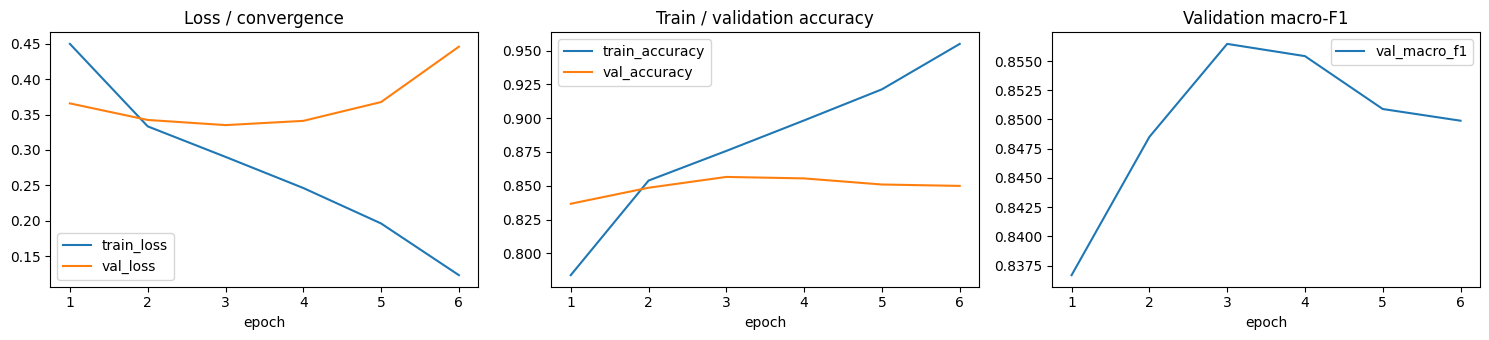

In [15]:
# 선택한 SentencePiece 모델의 오분류, 혼동 행렬, 학습 곡선.
# 검증에서 선택한 SentencePiece 모델의 첫 번째 seed로 오분류를 확인한다.
best_sp_name = selected.loc[selected.family.eq("sentencepiece"), "name"].iloc[0]
error_predictions = prediction_frames[(best_sp_name, MODEL_SEEDS[0])].copy()
print(classification_report(error_predictions.label, error_predictions.prediction,
                            labels=[0, 1], target_names=["negative", "positive"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(error_predictions.label, error_predictions.prediction,
                                        labels=[0, 1], display_labels=["negative", "positive"], cmap="Blues")
plt.title(f"{best_sp_name}, seed={MODEL_SEEDS[0]}")
plt.tight_layout()
plt.savefig(RUN_DIR / "sentencepiece_confusion_matrix.png", dpi=160)
plt.show()
errors = error_predictions.query("label != prediction").copy()
errors["confidence"] = np.maximum(errors.positive_probability, 1 - errors.positive_probability)
display(errors.sort_values("confidence", ascending=False).head(10))

# 같은 모델의 학습 곡선
history = pd.read_csv(RUN_DIR / f"{best_sp_name}_seed{MODEL_SEEDS[0]}_history.csv")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
history.plot(x="epoch", y=["train_loss", "val_loss"], ax=axes[0])
history.plot(x="epoch", y=["train_accuracy", "val_accuracy"], ax=axes[1])
history.plot(x="epoch", y="val_macro_f1", ax=axes[2])
axes[0].set_title("Loss / convergence")
axes[1].set_title("Train / validation accuracy")
axes[2].set_title("Validation macro-F1")
fig.tight_layout()
fig.savefig(RUN_DIR / "sentencepiece_learning_curve.png", dpi=160)
plt.show()


## 16. 저장한 모델로 새로운 리뷰 예측


In [16]:
# 저장한 토크나이저와 분류기로 새로운 리뷰 예측.
best_sp_spec = spec_by_name[best_sp_name]
inference_sp = spm.SentencePieceProcessor(model_proto=Path(best_sp_spec["tokenizer_path"]).read_bytes())
inference_row = validation_runs.loc[
    validation_runs.name.eq(best_sp_name) & validation_runs.seed.eq(MODEL_SEEDS[0])].iloc[0]
inference_model = BiGRUSentiment(inference_sp.get_piece_size()).to(DEVICE)
inference_model.load_state_dict(torch.load(inference_row.checkpoint, map_location=DEVICE, weights_only=True))
inference_model.eval()

@torch.inference_mode()
def predict_sentiment(reviews):
    if isinstance(reviews, str):
        reviews = [reviews]
    normalized = [normalize_text(review) for review in reviews]
    if not normalized or any(not text for text in normalized):
        raise ValueError("비어 있지 않은 리뷰를 1개 이상 입력하세요.")
    matrix, _, _ = sp_tokenize(inference_sp, normalized, maxlen=CFG["max_len"])
    lengths = torch.tensor((matrix != 0).sum(axis=1), dtype=torch.long)
    logits = inference_model(torch.from_numpy(matrix).long().to(DEVICE), lengths)
    probabilities = torch.sigmoid(logits).cpu().numpy()
    return pd.DataFrame({"review": reviews, "positive_probability": probabilities,
                         "prediction": np.where(probabilities >= 0.5, "긍정", "부정")})

display(predict_sentiment(["배우들의 연기가 훌륭하고 끝까지 몰입했어요!",
                           "지루하고 내용도 엉성해서 시간이 아까웠다.",
                           "기대 안 했는데 생각보다 괜찮네요 ㅋㅋ"]))


,review,positive_probability,prediction
0,배우들의 연기가 훌륭하고 끝까지 몰입했어요!,0.995856,긍정
1,지루하고 내용도 엉성해서 시간이 아까웠다.,0.000296,부정
2,기대 안 했는데 생각보다 괜찮네요 ㅋㅋ,0.935781,긍정


## 17. 실험 결과 요약


In [17]:
# 실제 실행 결과 요약.
best_sp_validation = selected.loc[selected.family.eq("sentencepiece")].iloc[0]
sp_test_score = test_summary.loc[test_summary.name.eq(best_sp_name), "test_macro_f1_mean"].iloc[0]
lines = [f"**실행 모드:** `{RUN_MODE}` / **분류기 seed 수:** {len(MODEL_SEEDS)}",
         f"검증으로 선택한 SentencePiece: `{best_sp_name}` "
         f"(검증 macro-F1 평균 {best_sp_validation.val_macro_f1_mean:.4f}, "
         f"테스트 macro-F1 평균 {sp_test_score:.4f})."]
for row in test_summary.loc[test_summary.family.eq("konlpy")].itertuples():
    difference = (sp_test_score - row.test_macro_f1_mean) * 100
    lines.append(f"`{row.model_type}` 대비 SentencePiece의 테스트 macro-F1 차이: "
                 f"{difference:+.2f} %p (해당 실험의 관측값).")
skipped = status_df.loc[status_df.status.eq("skipped"), "analyzer"].tolist()
if skipped:
    lines.append("실행하지 못한 분석기: " + ", ".join(skipped) + ". 사유는 analyzer_status.csv 참조.")
if RUN_MODE == "smoke":
    lines.append("**이 결과는 작은 샘플/짧은 학습으로 확인한 값이며 과제의 최종 성능 결론에 사용할 수 없습니다.**")
if len(MODEL_SEEDS) == 1:
    lines.append("단일 seed이므로 표준편차를 계산하지 않았습니다. 작은 차이의 안정성은 반복 실험이 필요합니다.")
report_markdown = "\n\n".join(lines)
display(Markdown(report_markdown))
print("모든 결과 파일:", RUN_DIR.resolve())


**실행 모드:** `full` / **분류기 seed 수:** 1

검증으로 선택한 SentencePiece: `sp_unigram_4000` (검증 macro-F1 평균 0.8565, 테스트 macro-F1 평균 0.8494).

`okt` 대비 SentencePiece의 테스트 macro-F1 차이: +0.28 %p (해당 실험의 관측값).

단일 seed이므로 표준편차를 계산하지 않았습니다. 작은 차이의 안정성은 반복 실험이 필요합니다.

모든 결과 파일: /content/nsmc_artifacts/full_5cccd57e03e0


## 18. 다각도 비교 분석·정확도 80% 확인·결과 저장


,tokenizer,review,pieces,tokens
0,sp_unigram_4000,재미없을 줄 알았는데 정말 재미있었다!,▁재미없 | 을 | ▁줄 | ▁알았는데 | ▁정말 | ▁재미있었 | 다 | !,8
1,sp_unigram_4000,연기는 좋지만 이야기가 너무 지루하다.,▁연기는 | ▁좋 | 지만 | ▁이야기 | 가 | ▁너무 | ▁지루하다 | .,8
2,sp_unigram_4000,와이건진짜꿀잼ㅋㅋ 두번보고싶음,▁와 | 이건 | 진짜 | 꿀잼 | ㅋㅋ | ▁두번 | 보고 | 싶 | 음,9
3,sp_unigram_4000,배우도 연출도 별로라 시간이 아까워요.,▁배우 | 도 | ▁연출 | 도 | ▁별로 | 라 | ▁시간이 | ▁아까워 | 요 | .,10
4,sp_unigram_8000,재미없을 줄 알았는데 정말 재미있었다!,▁재미없을 | ▁줄 | ▁알았는데 | ▁정말 | ▁재미있었다 | !,6
5,sp_unigram_8000,연기는 좋지만 이야기가 너무 지루하다.,▁연기는 | ▁좋지만 | ▁이야기가 | ▁너무 | ▁지루하다 | .,6
6,sp_unigram_8000,와이건진짜꿀잼ㅋㅋ 두번보고싶음,▁와 | 이건 | 진짜 | 꿀잼 | ㅋㅋ | ▁두번 | 보고 | 싶 | 음,9
7,sp_unigram_8000,배우도 연출도 별로라 시간이 아까워요.,▁배우 | 도 | ▁연출도 | ▁별로 | 라 | ▁시간이 | ▁아까워 | 요 | .,9
8,sp_unigram_16000,재미없을 줄 알았는데 정말 재미있었다!,▁재미없을 | ▁줄 | ▁알았는데 | ▁정말 | ▁재미있었다 | !,6
9,sp_unigram_16000,연기는 좋지만 이야기가 너무 지루하다.,▁연기는 | ▁좋지만 | ▁이야기가 | ▁너무 | ▁지루하다 | .,6


,name,requested_vocab,actual_vocab,parameters,val_accuracy_mean,val_macro_f1_mean,unk_fraction,mean_tokens,truncated_fraction
0,sp_unigram_4000,4000,4000,710401,0.856536,0.856467,0.000943,20.332260,0.0
1,sp_unigram_8000,8000,8000,1222401,0.854619,0.854618,0.001097,17.481613,0.0
2,sp_unigram_16000,16000,16000,2246401,0.854140,0.854017,0.001229,15.603095,0.0
3,morph_okt_8000,8000,8000,1222401,0.854003,0.853988,0.123137,14.736629,0.0
4,sp_bpe_8000,8000,8000,1222401,0.853386,0.853385,0.001120,17.113949,0.0
5,sp_bpe_4000,4000,4000,710401,0.850921,0.850910,0.000964,19.880983,0.0
6,sp_bpe_16000,16000,16000,2246401,0.846401,0.846349,0.001253,15.302198,0.0


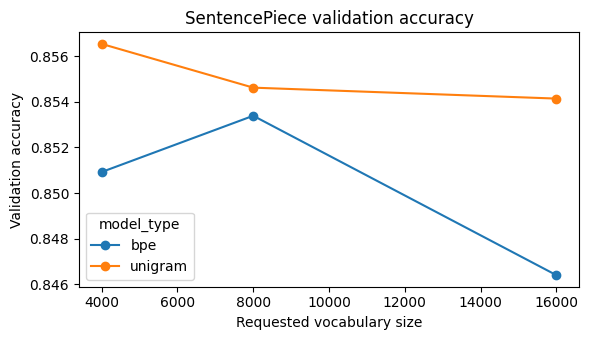

,name,seed,test_accuracy,test_macro_f1,test_roc_auc
0,sp_unigram_4000,42,0.849477,0.849435,0.930029


,seed,epochs_run,first_train_loss,last_train_loss,first_val_loss,best_val_loss,last_val_accuracy
0,42,6,0.449886,0.12315,0.365847,0.33515,0.849894


### 실제 실험 결과 해석

학습 131,422개 / 검증 14,603개 / 테스트 48,358개로 실행했다.

검증 Accuracy로 선택한 SentencePiece는 `sp_unigram_4000`이다. 테스트 Accuracy 평균은 **84.95%**, seed별 최소값은 **84.95%**이다.

루브릭 2의 정확도 80% 조건: **충족**. 수렴 여부는 학습·검증 손실과 Accuracy 곡선을 함께 확인한다.

**bpe 어휘 크기 비교:** 요청 어휘 4,000 → 16,000, 실제 어휘 4,000 → 16,000에서 검증 Accuracy 차이는 -0.45 %p다. 검증 UNK 비율은 0.096% → 0.125%, 평균 토큰 길이는 19.88 → 15.30였다. 파라미터 수는 710,401 → 2,246,401로 함께 달라졌다.

**unigram 어휘 크기 비교:** 요청 어휘 4,000 → 16,000, 실제 어휘 4,000 → 16,000에서 검증 Accuracy 차이는 -0.24 %p다. 검증 UNK 비율은 0.094% → 0.123%, 평균 토큰 길이는 20.33 → 15.60였다. 파라미터 수는 710,401 → 2,246,401로 함께 달라졌다.

**동일 요청 어휘 4,000:** BPE - unigram의 검증 Accuracy 차이는 -0.56 %p다.

**동일 요청 어휘 8,000:** BPE - unigram의 검증 Accuracy 차이는 -0.12 %p다.

**동일 요청 어휘 16,000:** BPE - unigram의 검증 Accuracy 차이는 -0.77 %p다.

**okt 비교:** 테스트 Accuracy 84.66%; 선택한 SentencePiece와의 차이(SP - 형태소)는 +0.29 %p다.

UNK·길이·파라미터 수의 변화는 함께 관찰된 현상이다. 정확도 차이의 원인이라고 단정하지 않고 위 토큰 분할과 오분류 사례를 함께 해석한다.

단일 seed 결과이므로 작은 점수 차이의 통계적 안정성은 확인하지 않았다.

결과 압축 파일: /content/nsmc_artifacts/nsmc_results_full_5cccd57e03e0.zip
VS Code에서 Ctrl+S로 표·그래프·분석 출력이 포함된 노트북을 저장하세요.


In [18]:
# 토큰 분할·성능·UNK·길이 비교, 정확도 80% 판정, 결과 저장.
# 1) 토크나이저별 동일 문장 분할: 부정 표현, 신조어, 띄어쓰기 오류를 포함한다.
probe_reviews = ["재미없을 줄 알았는데 정말 재미있었다!", "연기는 좋지만 이야기가 너무 지루하다.",
                 "와이건진짜꿀잼ㅋㅋ 두번보고싶음", "배우도 연출도 별로라 시간이 아까워요."]
probe_rows = []
for spec in specs:
    for text in probe_reviews:
        if spec["family"] == "sentencepiece":
            pieces = spec["sp"].encode(text, out_type=str)
        elif spec["analyzer"] == "okt":
            pieces = analyzers["okt"].morphs(text, norm=False, stem=False)
        else:
            pieces = analyzers[spec["analyzer"]].morphs(text)
        probe_rows.append({"tokenizer": spec["name"], "review": text, "pieces": " | ".join(pieces),
                           "tokens": len(pieces)})
probe_df = pd.DataFrame(probe_rows)
display(probe_df)
probe_df.to_csv(RUN_DIR / "tokenization_examples.csv", index=False, encoding="utf-8-sig")

# 2) Accuracy와 F1을 한 표에서 비교하고 검증 토큰화 통계를 연결한다.
comparison = validation_summary.merge(
    diagnostics_df.query("split == 'validation'").drop(columns="split"), on="name", how="left")
comparison.to_csv(RUN_DIR / "comprehensive_comparison.csv", index=False)
display(comparison[["name", "requested_vocab", "actual_vocab", "parameters", "val_accuracy_mean",
                    "val_macro_f1_mean", "unk_fraction", "mean_tokens", "truncated_fraction"]])
accuracy_pivot = sp_summary.pivot(index="requested_vocab", columns="model_type", values="val_accuracy_mean")
ax = accuracy_pivot.plot(marker="o", figsize=(6, 3.5), title="SentencePiece validation accuracy")
ax.set(xlabel="Requested vocabulary size", ylabel="Validation accuracy")
plt.tight_layout()
plt.savefig(RUN_DIR / "sentencepiece_accuracy_comparison.png", dpi=160)
plt.show()

# 3) 선택한 SentencePiece의 모든 seed 결과를 직접 공개한다.
sp_test_runs = test_runs.loc[test_runs.name.eq(best_sp_name)].copy()
display(sp_test_runs[["name", "seed", "test_accuracy", "test_macro_f1", "test_roc_auc"]])
sp_accuracy_mean = float(sp_test_runs.test_accuracy.mean())
sp_accuracy_min = float(sp_test_runs.test_accuracy.min())
accuracy_pass = RUN_MODE == "full" and sp_accuracy_min >= 0.80
rubric_status = {
    "mode": RUN_MODE, "selected_sentencepiece": best_sp_name,
    "train_rows": len(train_df), "validation_rows": len(val_df), "test_rows": len(test_df),
    "test_accuracy_mean": sp_accuracy_mean, "test_accuracy_min_across_seeds": sp_accuracy_min,
    "accuracy_threshold": 0.80, "rubric2_accuracy_pass": accuracy_pass,
    "convergence_evidence": "sentencepiece_learning_curve.png and per-seed history CSV",
    "comparison_configurations": len(validation_summary),
    "analyzers": list(analyzers), "model_seeds": MODEL_SEEDS,
}
save_json(RUN_DIR / "rubric_assessment.json", rubric_status)
convergence_rows = []
for seed in MODEL_SEEDS:
    curve = pd.read_csv(RUN_DIR / f"{best_sp_name}_seed{seed}_history.csv")
    convergence_rows.append({"seed": seed, "epochs_run": len(curve),
                             "first_train_loss": float(curve.train_loss.iloc[0]),
                             "last_train_loss": float(curve.train_loss.iloc[-1]),
                             "first_val_loss": float(curve.val_loss.iloc[0]),
                             "best_val_loss": float(curve.val_loss.min()),
                             "last_val_accuracy": float(curve.val_accuracy.iloc[-1])})
display(pd.DataFrame(convergence_rows))

analysis_lines = [
    "### 실제 실험 결과 해석",
    f"학습 {len(train_df):,}개 / 검증 {len(val_df):,}개 / 테스트 {len(test_df):,}개로 실행했다.",
    f"검증 Accuracy로 선택한 SentencePiece는 `{best_sp_name}`이다. "
    f"테스트 Accuracy 평균은 **{sp_accuracy_mean:.2%}**, seed별 최소값은 **{sp_accuracy_min:.2%}**이다.",
    f"루브릭 2의 정확도 80% 조건: **{'충족' if accuracy_pass else '미충족 / full 실행 결과 확인 필요'}**. "
    "수렴 여부는 학습·검증 손실과 Accuracy 곡선을 함께 확인한다.",
]
for model_type, group in comparison.query("family == 'sentencepiece'").groupby("model_type"):
    group = group.sort_values("requested_vocab")
    small, large = group.iloc[0], group.iloc[-1]
    delta = (large.val_accuracy_mean - small.val_accuracy_mean) * 100
    analysis_lines.append(
        f"**{model_type} 어휘 크기 비교:** 요청 어휘 {small.requested_vocab:,} → {large.requested_vocab:,}, "
        f"실제 어휘 {small.actual_vocab:,} → {large.actual_vocab:,}에서 검증 Accuracy 차이는 {delta:+.2f} %p다. "
        f"검증 UNK 비율은 {small.unk_fraction:.3%} → {large.unk_fraction:.3%}, "
        f"평균 토큰 길이는 {small.mean_tokens:.2f} → {large.mean_tokens:.2f}였다. "
        f"파라미터 수는 {small.parameters:,} → {large.parameters:,}로 함께 달라졌다.")
for vocab_size, group in comparison.query("family == 'sentencepiece'").groupby("requested_vocab"):
    by_type = group.set_index("model_type")
    if {"bpe", "unigram"}.issubset(by_type.index):
        delta = (by_type.loc["bpe", "val_accuracy_mean"] - by_type.loc["unigram", "val_accuracy_mean"]) * 100
        analysis_lines.append(f"**동일 요청 어휘 {vocab_size:,}:** BPE - unigram의 검증 Accuracy 차이는 {delta:+.2f} %p다.")
for row in test_summary.loc[test_summary.family.eq("konlpy")].itertuples():
    delta = (sp_accuracy_mean - row.test_accuracy_mean) * 100
    analysis_lines.append(f"**{row.model_type} 비교:** 테스트 Accuracy {row.test_accuracy_mean:.2%}; "
                          f"선택한 SentencePiece와의 차이(SP - 형태소)는 {delta:+.2f} %p다.")
analysis_lines.append("UNK·길이·파라미터 수의 변화는 함께 관찰된 현상이다. "
                      "정확도 차이의 원인이라고 단정하지 않고 위 토큰 분할과 오분류 사례를 함께 해석한다.")
if len(MODEL_SEEDS) == 1:
    analysis_lines.append("단일 seed 결과이므로 작은 점수 차이의 통계적 안정성은 확인하지 않았다.")
if RUN_MODE == "smoke":
    analysis_lines.append("**이 실행은 동작 확인용이므로 제출용 성능이나 수렴 결론으로 사용할 수 없다.**")
analysis_text = "\n\n".join(analysis_lines)
display(Markdown(analysis_text))
(RUN_DIR / "rubric_report.txt").write_text(analysis_text, encoding="utf-8")

# 4) 세부 결과와 모델을 묶어 커널 저장소에 보관한다. 노트북 출력도 반드시 저장한다.
archive_path = shutil.make_archive(str(RUN_DIR.parent / f"nsmc_results_{RUN_DIR.name}"), "zip", RUN_DIR)
print("결과 압축 파일:", archive_path)
print("VS Code에서 Ctrl+S로 표·그래프·분석 출력이 포함된 노트북을 저장하세요.")
